# ResNet18: transferencia visual y ajuste fino

Esta notebook compara un modelo profundo para **EMERGENCY** frente a **NON_EMERGENCY**,
utilizando espectrogramas Log-Mel numéricos de 64 bandas. Comparte las particiones y reglas
de evaluación con regresión logística, Random Forest, SVM y la otra arquitectura profunda.

Los corpus de desarrollo son AudioSet-EV v2, sireNNet y A3Siren-Recordings. LSSiren permanece
reservado para evaluación predictiva posterior. Las ventanas heredan etiquetas de archivo o
track y no constituyen observaciones independientes. La fuente no adelanta resultados de
clasificación, robustez ni evaluación externa.


## 1. Insumos y configuración

Adjunta un paquete completo de preparación v3 o v2. Si hay varios, selecciona `prepared_zip` o `prepared_root`. El ZIP de reportes no es un insumo de entrenamiento. La semilla es 42 y el presupuesto se fija antes de consultar la validación.


In [1]:
CFG = {
    "seed": 42,
    "prepared_root": None,
    "search_roots": ["/kaggle/input"],
    "output_base": "/kaggle/working/entrenamiento",
    "metadata_file": "metadata/metadata_segments.csv",
    "file_metadata_file": None,
    "preparation_config": "config/preparation_config.json",
    "split_files": {
        "train": "splits/train.csv",
        "validation": "splits/validation.csv",
        "generalization": "splits/generalization.csv",
    },
    "column_map": {},
    "label_map": {"NON_EMERGENCY": 0, "EMERGENCY": 1},
    "dataset_aliases": {
        "AudioSet-EV": "AudioSet-EV v2",
        "audioset-ev": "AudioSet-EV v2",
        "audioset_ev": "AudioSet-EV v2",
        "sirennet": "sireNNet",
        "SireNNet": "sireNNet",
        "a3s-rec": "A3Siren-Recordings",
        "A3Siren": "A3Siren-Recordings",
        "lssiren": "LSSiren",
    },
    "development_corpora": ["AudioSet-EV v2", "sireNNet", "A3Siren-Recordings"],
    "holdout_corpus": "LSSiren",
    "additional_group_columns": [
        "source_video_id",
        "original_recording_id",
        "augmentation_parent_id",
    ],
    "require_original_group_column": None,
    "cv_folds": 3,
    "target_recall": 0.9,
    "target_fpr": 0.1,
    "bootstrap_repeats": 500,
    "cpu_workers": 2,
    "latency_warmup": 20,
    "latency_repeats": 100,
    "throughput_batch": 2048,
    "allow_cpu": False,
    "max_gpus": 2,
    "batch_size": 128,
    "loader_workers": 0,
    "amp": True,
    "representation_manifest": "metadata/representation_manifest.csv",
    "representation_template": None,
    "path_prefix_map": {},
    "npz_key": "logmel",
    "transpose_logmel": False,
    "n_mels": 64,
    "disk_reserve_gib": 2,
    "normalization_chunk": 256,
    "max_epochs": 15,
    "patience": 3,
    "early_stop_min_delta": 0.0001,
    "inner_stop_folds": 5,
    "gradient_clip": 5.0,
    "head_warmup_epochs": 2,
    "backbone_lr_multiplier": 0.1,
    "pretrained_weights_path": None,
    "model_name": "05_resnet18",
    "display_name": "ResNet18: transferencia visual y ajuste fino",
    "model_kind": "resnet",
    "candidates": [
        {"lr": 0.001, "weight_decay": 0.0001, "dropout": 0.3},
        {"lr": 0.0003, "weight_decay": 0.0001, "dropout": 0.5},
    ],
    "prepared_zip": None,
    "prepared_cache": "/kaggle/working/prepared_cache",
    "unzip_reserve_gib": 2.0,
    "heartbeat_seconds": 30,
    "tensorboard": True,
    "batch_log_every": 100,
}

In [2]:
def validate_training_config(config):
    for key in [
        "cv_folds",
        "cpu_workers",
        "bootstrap_repeats",
        "latency_repeats",
        "latency_warmup",
    ]:
        if not isinstance(config[key], int) or config[key] < 1:
            raise ValueError(f"{key} debe ser un entero positivo.")
    if config["cv_folds"] < 2 or not config["candidates"]:
        raise ValueError("Se requieren al menos dos folds y un candidato.")
    if not 0 < config["target_recall"] <= 1 or not 0 < config["target_fpr"] <= 1:
        raise ValueError("Metas de recall/FPR fuera de rango.")
    if config["label_map"] != {"NON_EMERGENCY": 0, "EMERGENCY": 1}:
        raise ValueError("EMERGENCY debe ser la clase positiva, codificada como 1.")
    if config["model_kind"] in ["cnn", "resnet"]:
        for key in [
            "batch_size",
            "max_epochs",
            "patience",
            "max_gpus",
            "normalization_chunk",
        ]:
            if not isinstance(config[key], int) or config[key] < 1:
                raise ValueError(f"{key} debe ser un entero positivo.")
        if config["loader_workers"] != 0:
            raise ValueError(
                "Esta versión autocontenida utiliza loader_workers=0 para evitar procesos de notebook."
            )
        if (
            config["model_kind"] == "resnet"
            and config["max_epochs"] <= config["head_warmup_epochs"]
        ):
            raise ValueError(
                "max_epochs debe permitir al menos una época de ajuste fino."
            )

In [3]:
validate_training_config(CFG)

### Dependencias

Se utilizan las bibliotecas disponibles en Kaggle. Las versiones efectivas y el hardware se registran con cada ejecución; no se actualizan paquetes automáticamente.


In [4]:
import os
import sys
import json
import time
import hashlib
import platform
import shutil
import random
import subprocess
import gc
import zipfile
import stat

from pathlib import Path

from datetime import datetime, timezone

from importlib.metadata import version, PackageNotFoundError

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
)


try:
    from IPython.display import display
except ImportError:

    def display(value):
        print(value)

### Salida y trazabilidad

Cada ejecución escribe en una carpeta propia de `/kaggle/working`. Las fuentes montadas en `/kaggle/input` permanecen sin modificaciones.


In [5]:
def jsonable(x):
    if isinstance(x, np.generic):
        return x.item()
    if isinstance(x, np.ndarray):
        return x.tolist()
    if isinstance(x, Path):
        return str(x)
    raise TypeError(type(x).__name__)

In [6]:
def write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(
        json.dumps(obj, ensure_ascii=False, indent=2, default=jsonable),
        encoding="utf-8",
    )
    tmp.replace(path)

In [7]:
def sha_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

In [8]:
def save_table(name, rows):
    data = rows if isinstance(rows, pd.DataFrame) else pd.DataFrame(rows)
    data.to_csv(OUT / "tables" / name, index=False)
    return data

In [9]:
def fail(message):
    write_json(
        OUT / "reports" / "failure.json", {"status": "BLOCKED", "message": str(message)}
    )
    import zipfile

    diagnostic = OUT.parent / (OUT.name + "_diagnostico.zip")
    with zipfile.ZipFile(diagnostic, "w", zipfile.ZIP_DEFLATED) as z:
        for folder in ["config", "reports", "tables"]:
            for p in (OUT / folder).rglob("*"):
                if p.is_file():
                    z.write(p, str(p.relative_to(OUT)))
    print("Diagnóstico:", diagnostic)
    raise ValueError(message)

In [10]:
def environment():
    packages = {}
    for name in [
        "numpy",
        "pandas",
        "scikit-learn",
        "scipy",
        "matplotlib",
        "joblib",
        "torch",
        "torchvision",
    ]:
        try:
            packages[name] = version(name)
        except PackageNotFoundError:
            packages[name] = None
    try:
        gpu = subprocess.run(
            [
                "nvidia-smi",
                "--query-gpu=name,memory.total,driver_version",
                "--format=csv,noheader",
            ],
            capture_output=True,
            text=True,
            timeout=10,
        ).stdout.strip()
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = "No detectada"
    try:
        ram = (
            int(
                next(
                    line.split()[1]
                    for line in Path("/proc/meminfo").read_text().splitlines()
                    if line.startswith("MemTotal:")
                )
            )
            * 1024
        )
    except Exception:
        ram = None
    return {
        "python": sys.version,
        "platform": platform.platform(),
        "packages": packages,
        "cpu_count": os.cpu_count(),
        "ram_bytes": ram,
        "gpu_nvidia_smi": gpu,
        "disk_free_bytes": shutil.disk_usage(OUT).free,
    }

In [11]:
random.seed(CFG["seed"])

np.random.seed(CFG["seed"])

OUTPUT_BASE = Path(CFG["output_base"]).resolve()

if str(OUTPUT_BASE).startswith("/kaggle/input"):
    raise ValueError("La salida nunca puede ubicarse dentro de /kaggle/input.")

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = OUTPUT_BASE / CFG["model_name"] / RUN_ID

for folder in [
    "config",
    "tables",
    "figures",
    "reports",
    "models",
    "predictions",
    "checkpoints",
    "logs",
]:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

START_TIME = time.perf_counter()

write_json(OUT / "config" / "training_config.json", CFG)

ENV = environment()

write_json(OUT / "reports" / "environment.json", ENV)

display(
    pd.DataFrame(
        [
            {
                "modelo": CFG["model_name"],
                "salida": str(OUT),
                "CPU": ENV["cpu_count"],
                "GPU": ENV["gpu_nvidia_smi"],
            }
        ]
    )
)

RUNTIME_COSTS = []

,modelo,salida,CPU,GPU
0,05_resnet18,/kaggle/working/entrenamiento/05_resnet18/2026...,4,"Tesla T4, 15360 MiB, 580.178.04\nTesla T4, 153..."


In [12]:
def record_cost(phase, started):
    """Registra tiempo de pared; no confunde preparación con inferencia."""
    RUNTIME_COSTS.append({"phase": phase, "seconds": time.perf_counter() - started})

In [13]:
def safe_member_path(name):
    """Comprueba las rutas relativas antes de leer o extraer un artefacto."""
    from pathlib import PurePosixPath

    parts = PurePosixPath(name).parts
    if not parts or PurePosixPath(name).is_absolute() or ".." in parts or "\\" in name:
        raise ValueError(f"Ruta relativa inválida: {name}")
    return name

In [14]:
def atomic_zip(destination, entries):
    """Publica un ZIP completo únicamente después de verificar su CRC."""
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".partial")
    try:
        with zipfile.ZipFile(
            temporary, "w", zipfile.ZIP_DEFLATED, allowZip64=True
        ) as archive:
            for path, name in entries:
                archive.write(path, safe_member_path(name))
        with zipfile.ZipFile(temporary) as archive:
            invalid = archive.testzip()
            if invalid:
                raise ValueError(f"CRC inválido: {invalid}")
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination

### Registro de etapas

El registro de consola se complementa con `logs/training.log` y `logs/events.jsonl`. Un error guarda su traceback y un ZIP diagnóstico; los checkpoints contienen pesos y no garantizan una reanudación exacta del optimizador.


In [15]:
import logging
import traceback
import threading

from contextlib import contextmanager

try:
    from tqdm.auto import tqdm
except ImportError:

    class tqdm:
        def __init__(self, iterable=None, total=None, **kwargs):
            self.iterable = iterable

        def __iter__(self):
            return iter(self.iterable)

        def update(self, *args, **kwargs):
            pass

        def set_postfix(self, *args, **kwargs):
            pass

        def close(self):
            pass


try:
    import psutil
except ImportError:
    psutil = None

LOG_DIR = OUT / "logs"

LOG_DIR.mkdir(exist_ok=True)

LOGGER = logging.getLogger("doppler." + str(OUT))

LOGGER.setLevel(logging.INFO)

LOGGER.propagate = False

for h in LOGGER.handlers[:]:
    h.close()
    LOGGER.removeHandler(h)

handler = logging.FileHandler(LOG_DIR / "training.log", encoding="utf-8")

handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))

LOGGER.addHandler(handler)

console = logging.StreamHandler(sys.stdout)

console.setFormatter(logging.Formatter("%(asctime)s | %(message)s", datefmt="%H:%M:%S"))

LOGGER.addHandler(console)

In [16]:
def resource_snapshot():
    if psutil:
        return {"rss_mib": psutil.Process().memory_info().rss / 1024**2}
    return {}

In [17]:
def event(kind, console=True, **fields):
    record = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "event": kind,
        **resource_snapshot(),
        **fields,
    }
    with open(LOG_DIR / "events.jsonl", "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False, default=str) + "\n")
    if console:
        LOGGER.info(
            "%s | %s",
            kind,
            " | ".join(
                f"{k}={v:.5g}" if isinstance(v, float) else f"{k}={v}"
                for k, v in fields.items()
            ),
        )

In [18]:
def diagnostic_bundle():
    import zipfile

    target = OUT.parent / (OUT.name + "_diagnostico.zip")
    with zipfile.ZipFile(target, "w", zipfile.ZIP_DEFLATED) as z:
        for folder in ["config", "reports", "tables", "logs", "metadata"]:
            for p in (OUT / folder).rglob("*"):
                if p.is_file():
                    z.write(p, str(p.relative_to(OUT)))
    return str(target)

In [19]:
@contextmanager
def stage_guard(name):
    tick = time.perf_counter()
    event("stage_start", stage=name)
    try:
        yield
    except Exception as exc:
        error = traceback.format_exc()
        (LOG_DIR / "traceback.txt").write_text(error, encoding="utf-8")
        event(
            "stage_failed",
            stage=name,
            error=str(exc),
            seconds=time.perf_counter() - tick,
        )
        write_json(
            OUT / "reports/run_status.json",
            {"status": "FAILED", "stage": name, "error": str(exc)},
        )
        try:
            print("Diagnóstico guardado:", diagnostic_bundle())
        except Exception as diag_exc:
            print("No se pudo comprimir el diagnóstico:", diag_exc)
        raise
    else:
        event("stage_end", stage=name, seconds=time.perf_counter() - tick)

In [20]:
@contextmanager
def heartbeat(phase, **fields):
    stop = threading.Event()
    tick = time.perf_counter()

    def worker():
        while not stop.wait(CFG.get("heartbeat_seconds", 30)):
            event(
                "fit_running",
                phase=phase,
                elapsed_seconds=time.perf_counter() - tick,
                **fields,
            )

    thread = threading.Thread(target=worker, daemon=True)
    thread.start()
    try:
        yield
    finally:
        stop.set()
        thread.join(timeout=1)

In [21]:
write_json(OUT / "reports/run_status.json", {"status": "RUNNING"})

event("run_start", model=CFG.get("model_name", "preparation"), output=str(OUT))

20:05:27 | run_start | model=05_resnet18 | output=/kaggle/working/entrenamiento/05_resnet18/20261012T200526_749323Z


## 2. Lectura y contrato de datos

Las uniones utilizan `segment_id`, nunca la posición de una fila. Se comprueban cobertura de particiones, etiquetas y ambigüedades del paquete. La extracción y su caché verifican contenido.


In [22]:
with stage_guard("data_adapters"):
    ALIASES = {
        "segment_id": ["segment_id", "segment_uid"],
        "dataset": ["dataset", "corpus", "dataset_name"],
        "file_id": ["file_id", "source_file_id"],
        "track_id": ["track_id", "source_track_id"],
        "canonical_label": ["canonical_label", "label_binary", "target_label"],
        "original_label": ["original_label", "label_original"],
        "split": ["split", "partition", "subset"],
        "sha256": ["sha256", "source_sha256"],
        "original_path": ["original_path", "source_path"],
        "representation_path": [
            "representation_path",
            "path_to_representation",
            "logmel_path",
            "spectrogram_path",
        ],
    }

20:05:27 | stage_start | stage=data_adapters
20:05:27 | stage_end | stage=data_adapters | seconds=0.0015294


In [23]:
def canonicalize(df):
    # Las equivalencias adicionales se especifican como {columna_original: columna_canónica}.
    df = df.rename(columns=CFG["column_map"]).copy()
    if df.columns.duplicated().any():
        fail("El mapeo de columnas crea nombres duplicados.")
    for canonical, variants in ALIASES.items():
        found = [c for c in variants if c in df]
        if canonical not in df and len(found) == 1:
            df = df.rename(columns={found[0]: canonical})
        elif canonical not in df and len(found) > 1:
            fail(f"Columnas ambiguas para {canonical}: {found}")
    return df

In [24]:
def read_csv(path):
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    return canonicalize(df)

In [25]:
def zip_contract(path):
    required = [
        "features/acoustic_features.csv",
        "features/mfcc_features.csv",
        "splits/train.csv",
        "splits/validation.csv",
        "splits/generalization.csv",
        "config/preparation_config.json",
    ]
    try:
        with zipfile.ZipFile(path) as archive:
            names = set(archive.namelist())
            suffix = "metadata/metadata_segments.csv"
            roots = [name[: -len(suffix)] for name in names if name.endswith(suffix)]
            roots = [
                root for root in roots if all(root + name in names for name in required)
            ]
            if len(roots) == 1:
                return roots[0]
    except (OSError, zipfile.BadZipFile):
        return None
    return None

In [26]:
def unpack_prepared(path, prefix):
    """La caché comprueba contenido, incluso si una alteración conserva el tamaño."""
    started = time.perf_counter()
    with heartbeat("zip_sha256"):
        fingerprint = sha_file(path)
    cache = Path(CFG["prepared_cache"]).resolve()
    if cache == Path("/kaggle/input") or Path("/kaggle/input") in cache.parents:
        fail("prepared_cache debe estar fuera de /kaggle/input.")
    branch = "deep" if CFG["model_kind"] in ["cnn", "resnet"] else "tabular"
    cache.mkdir(parents=True, exist_ok=True)
    destination = cache / (fingerprint[:20] + "_" + branch)
    marker = destination / "EXTRACTION_COMPLETE.json"
    if marker.is_file():
        saved = json.loads(marker.read_text())
        valid = saved.get("zip_sha256") == fingerprint
        for name, expected in saved.get("members", {}).items():
            target = destination / safe_member_path(name)
            valid = valid and target.is_file() and sha_file(target) == expected
        if not valid or not saved.get("members"):
            fail("La caché cambió o está incompleta. Usa otra prepared_cache.")
        record_cost("verificacion_cache_zip", started)
        return destination
    if destination.exists():
        fail("Existe una extracción parcial. Usa otra prepared_cache.")
    with zipfile.ZipFile(path) as archive:
        chosen, seen = [], set()
        for info in archive.infolist():
            if info.is_dir() or not info.filename.startswith(prefix):
                continue
            name = safe_member_path(info.filename[len(prefix) :])
            if stat.S_ISLNK(info.external_attr >> 16) or name in seen:
                fail("El ZIP contiene enlaces simbólicos o nombres repetidos.")
            seen.add(name)
            if name.startswith("_staging/"):
                continue
            if name.startswith("representations/"):
                if (
                    branch == "tabular"
                    or name == "representations/logmel/generalization.npy"
                ):
                    continue
            chosen.append((info, name))
        needed = sum(info.file_size for info, _ in chosen)
        if shutil.disk_usage(cache).free < needed + CFG["unzip_reserve_gib"] * 1024**3:
            fail("Espacio insuficiente para extraer el paquete.")
        destination.mkdir()
        members = {}
        for info, name in tqdm(
            chosen, desc="Extraer insumos " + branch, unit="archivo"
        ):
            target = destination / name
            target.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(info) as source, target.open("wb") as output:
                shutil.copyfileobj(source, output, 1024 * 1024)
            members[name] = sha_file(target)
        write_json(marker, {"zip_sha256": fingerprint, "members": members})
    record_cost("extraccion_zip", started)
    return destination

In [27]:
def find_root():
    """Una sola exploración; las rutas explícitas tienen prioridad."""
    started = time.perf_counter()
    if CFG["prepared_root"] and CFG["prepared_zip"]:
        fail("Configura prepared_root o prepared_zip, no ambos.")
    if CFG["prepared_root"]:
        root = Path(CFG["prepared_root"]).resolve()
        if not (root / "metadata/metadata_segments.csv").is_file():
            fail(f"Falta el manifiesto de preparación en {root}.")
        record_cost("descubrimiento_insumos", started)
        return root
    if CFG["prepared_zip"]:
        path = Path(CFG["prepared_zip"])
        prefix = zip_contract(path)
        if prefix is None:
            fail(f"No es un paquete completo: {path}")
        record_cost("descubrimiento_insumos", started)
        return unpack_prepared(path, prefix)
    roots, archives = set(), []
    for base in CFG["search_roots"]:
        base = Path(base)
        if not base.exists():
            continue
        for directory, _, filenames in os.walk(base):
            directory = Path(directory)
            if directory.name == "metadata" and "metadata_segments.csv" in filenames:
                root = directory.parent
                if (root / "features/acoustic_features.csv").is_file():
                    roots.add(root)
            archives.extend(
                directory / name for name in filenames if name.lower().endswith(".zip")
            )
    candidates = [(path, zip_contract(path)) for path in sorted(set(archives))]
    candidates = [(path, prefix) for path, prefix in candidates if prefix is not None]
    if len(roots) + len(candidates) != 1:
        fail(
            "Se requiere un único paquete completo. Fija prepared_root o prepared_zip."
        )
    record_cost("descubrimiento_insumos", started)
    if roots:
        return next(iter(roots))
    return unpack_prepared(*candidates[0])

In [28]:
def required_path(relative):
    p = Path(relative)
    p = p if p.is_absolute() else ROOT / p
    if not p.is_file():
        fail(f"Falta el insumo requerido: {p}. Adjunta las salidas de preparación.")
    key = p.relative_to(ROOT).as_posix() if p.is_relative_to(ROOT) else str(p)
    if key not in INPUT_HASHES:
        INPUT_HASHES[key] = sha_file(p)
    return p

In [29]:
def merge_by_segment(left, right, origin):
    if "segment_id" not in right:
        fail(f"{origin}: falta segment_id. No se permite unir por posición de fila.")
    if right.segment_id.duplicated().any():
        fail(f"{origin}: segment_id repetido.")
    common = [c for c in right if c in left and c != "segment_id"]
    indexed = right.set_index("segment_id")
    if not left.segment_id.isin(indexed.index).all():
        fail(f"{origin}: faltan segmentos del manifiesto.")
    for c in common:
        r = left.segment_id.map(indexed[c]).astype(str)
        left_values = left[c].astype(str)
        present = left_values.ne("") & r.ne("")
        mismatch = left_values.to_numpy() != r.to_numpy()
        if c in CFG.get("feature_columns", []):
            ln = pd.to_numeric(left_values, errors="coerce").to_numpy(dtype=float)
            rn = pd.to_numeric(r, errors="coerce").to_numpy(dtype=float)
            mismatch = ~(
                np.isfinite(ln)
                & np.isfinite(rn)
                & np.isclose(ln, rn, rtol=1e-6, atol=1e-8)
            )
        if (present.to_numpy() & mismatch).any():
            fail(
                f"{origin}: conflicto en la columna {c}. Corrige el contrato de entrada."
            )
        left[c] = np.where(left_values.eq(""), r, left_values)
    return left.merge(
        right.drop(columns=common), on="segment_id", how="left", validate="one_to_one"
    )

In [30]:
def read_manifest():
    m = read_csv(required_path(CFG["metadata_file"]))
    # Puede completar metadata de archivo cuando la tabla de segmentos no repite esos atributos.
    if CFG["file_metadata_file"]:
        source = read_csv(required_path(CFG["file_metadata_file"]))
        keys = ["dataset", "file_id"]
        if not all(c in m and c in source for c in keys):
            fail("metadata de archivo requiere dataset y file_id en ambas tablas.")
        if source.duplicated(keys).any():
            fail("metadata de archivo contiene claves dataset+file_id repetidas.")
        idx = pd.MultiIndex.from_frame(m[keys])
        source = source.set_index(keys)
        if not idx.isin(source.index).all():
            fail("metadata de archivo no cubre todos los segmentos.")
        for c in source:
            if c in ["segment_id", "split", "start_time", "end_time"]:
                continue
            values = source[c].reindex(idx).to_numpy()
            if c not in m:
                m[c] = values
            else:
                conflict = m[c].ne("") & (values != "") & m[c].ne(values)
                if conflict.any():
                    fail(f"Metadata de archivo y segmento discrepan en {c}.")
                m[c] = np.where(m[c].eq(""), values, m[c])
    for c in ["segment_id", "dataset", "file_id", "canonical_label"]:
        if c not in m or m[c].eq("").any():
            fail(f"El manifiesto requiere {c} completo.")
    if m.segment_id.duplicated().any():
        fail("Hay segment_id duplicados.")
    assigned = []
    for split, filename in CFG["split_files"].items():
        s = read_csv(required_path(filename))
        if "segment_id" in s:
            keys = ["segment_id"]
        elif all(c in s for c in ["dataset", "file_id"]):
            keys = ["dataset", "file_id"]
        elif all(c in s for c in ["dataset", "track_id"]) and "track_id" in m:
            keys = ["dataset", "track_id"]
        else:
            fail(f"{filename}: se necesita segment_id o dataset+file_id/track_id.")
        if s.duplicated(keys).any():
            fail(f"{filename}: claves repetidas en la partición.")
        s = s[keys]
        if (
            not pd.MultiIndex.from_frame(s)
            .isin(pd.MultiIndex.from_frame(m[keys]))
            .all()
        ):
            fail(f"{filename}: contiene claves ajenas al manifiesto de segmentos.")
        hit = m[["segment_id"] + [c for c in keys if c != "segment_id"]].merge(
            s, on=keys, how="inner"
        )
        assigned.append(hit[["segment_id"]].assign(split_assigned=split))
    a = pd.concat(assigned, ignore_index=True)
    if a.segment_id.duplicated().any():
        fail("Un segmento pertenece a más de un archivo de split.")
    if set(a.segment_id) != set(m.segment_id):
        fail("Los splits no cubren exactamente los segmentos elegibles del manifiesto.")
    m = m.merge(a, on="segment_id", validate="one_to_one")
    if "split" in m:
        old = (
            m["split"]
            .str.lower()
            .replace(
                {"val": "validation", "valid": "validation", "test": "generalization"}
            )
        )
        if (old != m.split_assigned).any():
            fail("Split del manifiesto y archivos de partición no coinciden.")
    m["split"] = m.pop("split_assigned")
    label_map = CFG["label_map"]
    m["y"] = m.canonical_label.map(label_map)
    if m.y.isna().any():
        fail("Etiquetas canónicas desconocidas; no se inferirán a partir de carpetas.")
    m["y"] = m.y.astype(int)
    aliases = CFG["dataset_aliases"]
    m["dataset"] = m.dataset.map(lambda x: aliases.get(x, x))
    if not set(m.dataset).issubset(
        set(CFG["development_corpora"] + [CFG["holdout_corpus"]])
    ):
        fail("Hay corpus no reconocidos. Revisa dataset_aliases y el manifiesto.")
    holdout = m.dataset.eq(CFG["holdout_corpus"])
    if not holdout.any() or not (holdout == m.split.eq("generalization")).all():
        fail(
            "LSSiren debe estar exclusivamente en generalization y ser el único corpus externo."
        )
    return m.sort_values("segment_id").reset_index(drop=True)

### Integridad y grupos de origen

Se conservan los grupos publicados y se amplían con archivo, SHA-256, track y procedencia disponible. Las dependencias conocidas deben quedar juntas. LSSiren conserva exclusivamente su papel de reserva predictiva externa.


In [31]:
def verify_published_hashes(root, *, include_representations=False):
    """Contrasta el manifiesto publicado; permite paquetes históricos sin hashes."""
    started = time.perf_counter()
    path = root / "reports/artifact_hashes.json"
    if not path.is_file():
        if PREPARATION.get("protocol_version") in [
            "doppler-prepared-v2",
            "doppler-prepared-v3",
        ]:
            fail("Falta reports/artifact_hashes.json en el paquete versionado.")
        event(
            "legacy_hash_manifest_absent",
            notice="No se certifica integridad publicada del paquete histórico.",
        )
        return
    published = json.loads(path.read_text())
    if not published:
        fail("El manifiesto de hashes está vacío.")
    for name, expected in published.items():
        safe_member_path(name)
        if name.startswith("representations/"):
            if (
                not include_representations
                or name == "representations/logmel/generalization.npy"
            ):
                continue
        target = root / name
        if not target.is_file() or sha_file(target) != expected:
            fail(f"Hash publicado incorrecto o artefacto ausente: {name}")
        INPUT_HASHES[name] = expected
    record_cost("verificacion_hashes_publicados", started)

In [32]:
def attach_groups(m):
    parent = list(range(len(m)))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(i, j):
        a, b = root(i), root(j)
        if a != b:
            parent[max(a, b)] = min(a, b)

    def link(values):
        seen = {}
        for i, v in enumerate(values):
            if v is None or v == "":
                continue
            if v in seen:
                union(i, seen[v])
            else:
                seen[v] = i

    if "group_id" in m:
        m["preparation_group_id"] = m.group_id.copy()
        link(m.group_id.tolist())
    link([f"{d}|file|{f}" for d, f in zip(m.dataset, m.file_id)])
    if "original_path" in m:
        link([p if p else None for p in m.original_path])
    a3 = m.dataset.eq("A3Siren-Recordings")
    if a3.any() and ("track_id" not in m or m.loc[a3, "track_id"].eq("").any()):
        fail("A3Siren requiere track_id completo.")
    if "track_id" in m:
        link([f"{d}|track|{t}" if t else None for d, t in zip(m.dataset, m.track_id)])
    if "sha256" not in m or m.sha256.eq("").any():
        fail("Falta SHA-256 de origen para auditar duplicados conocidos.")
    link(m.sha256.tolist())
    for c in CFG["additional_group_columns"]:
        if c in m:
            namespace = (
                "recording"
                if c in ["original_recording_id", "augmentation_parent_id"]
                else c
            )
            link(
                [f"{d}|{namespace}|{v}" if v else None for d, v in zip(m.dataset, m[c])]
            )
    if "augmentation_parent_id" in m:
        link(
            [
                f"{d}|file|{v}" if v else None
                for d, v in zip(m.dataset, m.augmentation_parent_id)
            ]
        )
    if "augmentation_parent_id" in m:
        origins = {}
        for column in ["file_id", "original_recording_id"]:
            if column in m:
                for index, (dataset, value) in enumerate(zip(m.dataset, m[column])):
                    if value:
                        origins.setdefault((dataset, value), set()).add(root(index))
        for index, (dataset, value) in enumerate(
            zip(m.dataset, m.augmentation_parent_id)
        ):
            for origin in origins.get((dataset, value), []) if value else []:
                union(index, origin)
    members = {}
    for i in range(len(m)):
        members.setdefault(root(i), []).append(m.segment_id.iloc[i])
    ids = {
        k: hashlib.sha256("\n".join(sorted(v)).encode()).hexdigest()[:20]
        for k, v in members.items()
    }
    declared = {}
    if "preparation_group_id" in m:
        for i, value in enumerate(m.preparation_group_id):
            if value:
                declared.setdefault(root(i), set()).add(value)
    effective = {
        key: next(iter(declared[key])) if len(declared.get(key, set())) == 1 else value
        for key, value in ids.items()
    }
    m["group_id"] = [effective[root(i)] for i in range(len(m))]
    if "preparation_group_id" in m:
        save_table(
            "group_resolution.csv",
            m[["segment_id", "preparation_group_id", "group_id"]],
        )
    crossing = m.groupby("group_id").split.nunique()
    bad = crossing[crossing > 1]
    save_table(
        "leakage_audit.csv",
        [
            {
                "control": "known_group_crosses_splits",
                "cases": len(bad),
                "scope": "file, track, SHA256 y columnas de origen disponibles",
            }
        ],
    )
    if len(bad):
        save_table("cross_split_groups.csv", m[m.group_id.isin(bad.index)])
        fail(
            "Se detectaron dependencias conocidas entre splits. Repara la preparación antes de entrenar."
        )
    missing = [c for c in CFG["additional_group_columns"] if c not in m]
    limitations = [
        "SHA-256 solo controla duplicados binarios; no certifica independencia acústica.",
        "No se auditó similitud perceptual ni la verdad temporal de las etiquetas en esta notebook.",
        "sireNNet ya incluye aumentos; revisar procedencia de sus grabaciones.",
    ]
    write_json(
        OUT / "reports" / "independence_scope.json",
        {"missing_optional_columns": missing, "limitations": limitations},
    )
    if (
        CFG["require_original_group_column"]
        and CFG["require_original_group_column"] not in m
    ):
        fail("Falta la columna de grupos originales exigida por la configuración.")
    return m

In [33]:
with stage_guard("dependency_audit"):
    ROOT = find_root()

    INPUT_HASHES = {}

    read_start = time.perf_counter()

    PREPARATION = json.loads(required_path(CFG["preparation_config"]).read_text())

    ready = ROOT / "PREPARATION_READY.json"

    if (
        PREPARATION.get("protocol_version") == "doppler-prepared-v3"
        and not ready.is_file()
    ):
        fail("Un paquete v3 debe estar marcado READY.")

    if ready.is_file():
        contract = json.loads(ready.read_text())
        if contract.get("status") != "READY":
            fail("La preparación no está marcada READY.")
        version = PREPARATION.get("protocol_version")
        if (
            version in ["doppler-prepared-v2", "doppler-prepared-v3"]
            and contract.get("schema_version") != version
        ):
            fail("El marcador READY y la configuración discrepan en la versión.")
        if contract.get("features_scaled") is True:
            fail("El paquete tiene features ya escaladas.")
    else:
        event(
            "legacy_package",
            notice="Paquete histórico sin marcador v2; se auditan CSV, grupos y valores originales.",
        )

    write_json(OUT / "config" / "preparation_config_source.json", PREPARATION)

    verify_published_hashes(ROOT)

    MANIFEST = attach_groups(read_manifest())

    if ready.is_file() and PREPARATION.get("protocol_version") in [
        "doppler-prepared-v2",
        "doppler-prepared-v3",
    ]:
        if contract.get("segments") != len(MANIFEST):
            fail("El marcador READY no coincide con el número de segmentos.")

    record_cost("lectura_y_auditoria_metadata", read_start)

    save_table(
        "split_counts.csv",
        MANIFEST.groupby(["split", "dataset", "canonical_label"])
        .agg(
            segments=("segment_id", "size"),
            files=("file_id", "nunique"),
            known_groups=("group_id", "nunique"),
        )
        .reset_index(),
    )

    EXTERNAL = MANIFEST[MANIFEST.split.eq("generalization")].copy()

    DEV = (
        MANIFEST[MANIFEST.split.isin(["train", "validation"])]
        .copy()
        .reset_index(drop=True)
    )

    TRAIN = DEV[DEV.split.eq("train")].copy().reset_index(drop=True)

    VALID = DEV[DEV.split.eq("validation")].copy().reset_index(drop=True)

    for name, part in [("train", TRAIN), ("validation", VALID)]:
        if set(part.y) != {0, 1}:
            fail(f"{name} debe contener ambas clases.")

    save_table(
        "data_contract.csv",
        [{"field": c, "nonempty": int(DEV[c].astype(str).ne("").sum())} for c in DEV],
    )

    print(
        "Corpus externo reservado:", CFG["holdout_corpus"], "segmentos:", len(EXTERNAL)
    )

    display(pd.read_csv(OUT / "tables" / "split_counts.csv"))

20:05:27 | stage_start | stage=dependency_audit
Corpus externo reservado: LSSiren segmentos: 6364


,split,dataset,canonical_label,segments,files,known_groups
0,generalization,LSSiren,EMERGENCY,2888,894,894
1,generalization,LSSiren,NON_EMERGENCY,3476,766,766
2,train,A3Siren-Recordings,EMERGENCY,944,48,6
3,train,A3Siren-Recordings,NON_EMERGENCY,1560,40,5
4,train,AudioSet-EV v2,EMERGENCY,31333,6312,6312
5,train,AudioSet-EV v2,NON_EMERGENCY,83143,16706,16706
6,train,sireNNet,EMERGENCY,997,997,997
7,train,sireNNet,NON_EMERGENCY,337,337,337
8,validation,A3Siren-Recordings,EMERGENCY,40,8,1
9,validation,A3Siren-Recordings,NON_EMERGENCY,312,8,1


20:06:22 | stage_end | stage=dependency_audit | seconds=54.89


## 3. Protocolo de evaluación

La búsqueda utiliza tres folds por grupos dentro de `train`. Cada transformación aprendida se ajusta con el entrenamiento de su fold. La selección maximiza F1 macro medio, con desempate por recall y tiempo de ajuste.

El umbral se elige con predicciones OOF del candidato seleccionado: recall ≥ 0,90 y FPR < 0,10. Si las restricciones son inviables, se conserva el máximo F1 macro OOF y se registra esa condición. Las métricas OOF son evidencia de desarrollo, no una evaluación independiente después de seleccionar.


In [34]:
def create_folds(frame, n_splits, seed):
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    result = []
    for tr, va in splitter.split(np.zeros(len(frame)), frame.y, frame.group_id):
        if set(frame.iloc[tr].y) != {0, 1} or set(frame.iloc[va].y) != {0, 1}:
            fail(
                "Un fold no contiene ambas clases. Revisa los grupos o reduce n_splits explícitamente."
            )
        if set(frame.iloc[tr].group_id) & set(frame.iloc[va].group_id):
            fail("Un grupo cruza el entrenamiento y la validación del fold.")
        result.append((tr, va))
    return result

In [35]:
with stage_guard("folds_metrics"):
    FOLDS = create_folds(TRAIN, CFG["cv_folds"], CFG["seed"])

    fold_map = TRAIN[["segment_id", "dataset", "group_id", "canonical_label"]].copy()

    fold_map["validation_fold"] = -1

    for f, (tr, va) in enumerate(FOLDS):
        fold_map.loc[va, "validation_fold"] = f

    save_table("cv_assignments.csv", fold_map)

    save_table(
        "cv_distribution.csv",
        fold_map.groupby(["validation_fold", "dataset", "canonical_label"])
        .agg(segments=("segment_id", "size"), groups=("group_id", "nunique"))
        .reset_index(),
    )

    FOLD_HASH = hashlib.sha256(fold_map.to_csv(index=False).encode()).hexdigest()

20:06:22 | stage_start | stage=folds_metrics
20:06:28 | stage_end | stage=folds_metrics | seconds=5.6883


In [36]:
def metrics(y, score, threshold):
    y = np.asarray(y, dtype=int)
    score = np.asarray(score, dtype=float)
    pred = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "n": len(y),
        "accuracy": accuracy_score(y, pred),
        "precision_emergency": precision_score(y, pred, zero_division=0),
        "recall_emergency": recall_score(y, pred, zero_division=0),
        "f1_macro": f1_score(y, pred, labels=[0, 1], average="macro", zero_division=0),
        "fpr": fp / (fp + tn) if fp + tn else np.nan,
        "roc_auc": roc_auc_score(y, score) if len(np.unique(y)) == 2 else np.nan,
        "average_precision": average_precision_score(y, score)
        if len(np.unique(y)) == 2
        else np.nan,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "threshold": float(threshold),
    }

In [37]:
def threshold_search(y, scores):
    # Barrido exacto por scores únicos; evita 1000 matrices de confusión completas.
    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)
    if (
        len(y) != len(scores)
        or not len(y)
        or not np.isfinite(scores).all()
        or set(y) != {0, 1}
    ):
        raise ValueError("El umbral requiere scores finitos, alineados y ambas clases.")
    order = np.argsort(-scores, kind="stable")
    s = scores[order]
    y = y[order]
    last = np.r_[np.flatnonzero(np.diff(s) != 0), len(s) - 1]
    tp = np.cumsum(y)[last]
    fp = (last + 1) - tp
    fn = y.sum() - tp
    tn = len(y) - y.sum() - fp

    def safe(a, b):
        return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b != 0)

    recall = safe(tp, tp + fn)
    fpr = safe(fp, fp + tn)
    f1 = (safe(2 * tp, 2 * tp + fp + fn) + safe(2 * tn, 2 * tn + fp + fn)) / 2
    t = pd.DataFrame(
        {"threshold": s[last], "f1_macro": f1, "recall_emergency": recall, "fpr": fpr}
    )
    # Incluye también el clasificador que no predice positivos.
    t = pd.concat(
        [t, pd.DataFrame([metrics(y, s, np.nextafter(s.max(), np.inf))])],
        ignore_index=True,
    )
    feasible = t[
        (t.recall_emergency >= CFG["target_recall"]) & (t.fpr < CFG["target_fpr"])
    ]
    pool = feasible if len(feasible) else t
    chosen = pool.sort_values(
        ["f1_macro", "recall_emergency", "threshold"], ascending=[False, False, False]
    ).iloc[0]
    return float(chosen.threshold), len(feasible) > 0, t

In [38]:
def predictions_frame(frame, scores, threshold):
    cols = ["segment_id", "dataset", "file_id", "group_id", "canonical_label", "y"]
    if "track_id" in frame:
        cols.append("track_id")
    return (
        frame[cols]
        .copy()
        .assign(score=scores, prediction=(np.asarray(scores) >= threshold).astype(int))
    )

In [39]:
def select_candidate(results):
    r = pd.DataFrame(results)
    agg = (
        r.groupby("trial")
        .agg(
            f1_mean=("f1_macro", "mean"),
            f1_std=("f1_macro", "std"),
            recall_mean=("recall_emergency", "mean"),
            fpr_mean=("fpr", "mean"),
            fit_seconds=("fit_seconds", "sum"),
            folds_completed=("fold", "nunique"),
        )
        .reset_index()
    )
    agg = agg[agg.folds_completed.eq(CFG["cv_folds"])]
    if agg.empty:
        fail("Ningún candidato completó todos los folds con ajuste válido.")
    # Regla única, predefinida: F1 macro medio; empate recall; después tiempo de ajuste.
    agg = agg.sort_values(
        ["f1_mean", "recall_mean", "fit_seconds"], ascending=[False, False, True]
    )
    save_table("hyperparameter_summary.csv", agg)
    return int(agg.iloc[0].trial), agg

### Métricas e incertidumbre

EMERGENCY es la clase positiva. Se exportan accuracy, precisión, recall, F1 macro, FPR, ROC-AUC y average precision, con resultados globales y por corpus. Los intervalos remuestrean grupos completos. La agregación por máximo de score es un análisis adicional y no una evaluación temporal de eventos.


In [40]:
def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.savefig(OUT / "figures" / f"{name}.svg", bbox_inches="tight")
    plt.show()
    plt.close()

In [41]:
def make_reports(final_scores, oof_scores, threshold, selected, summary, runtime_rows):
    save_table("validation_metrics.csv", [metrics(VALID.y, final_scores, threshold)])
    save_table(
        "validation_by_corpus.csv",
        [
            dict(dataset=d, **metrics(g.y, final_scores[g.index], threshold))
            for d, g in VALID.groupby("dataset")
        ],
    )
    # Evaluación por grupo: etiqueta positiva si existe un segmento positivo, score máximo.
    pred = predictions_frame(VALID, final_scores, threshold)
    pred.to_csv(OUT / "predictions" / "validation_predictions.csv", index=False)
    predictions_frame(TRAIN, oof_scores, threshold).to_csv(
        OUT / "predictions" / "selected_oof_predictions.csv", index=False
    )
    grouped = (
        pred.groupby(["dataset", "group_id"])
        .agg(y=("y", "max"), score=("score", "max"))
        .reset_index()
    )
    save_table(
        "validation_group_any_event.csv", [metrics(grouped.y, grouped.score, threshold)]
    )
    write_json(
        OUT / "reports" / "group_metric_definition.json",
        {
            "label": "any positive segment",
            "score": "maximum segment score",
            "limitation": "Grupos largos tienen más oportunidades de falsa alarma; no es evaluación temporal por evento.",
        },
    )
    save_table("computational_cost.csv", RUNTIME_COSTS + runtime_rows)
    plot_validation_figures(final_scores, threshold, summary, runtime_rows)
    # IC por bootstrap de grupos completos. Sin tratar ventanas solapadas como independientes.
    intervals = cluster_bootstrap_intervals(
        VALID.y.to_numpy(),
        final_scores,
        VALID.group_id.to_numpy(),
        threshold,
        CFG["bootstrap_repeats"],
        CFG["seed"],
    )
    save_table("validation_cluster_bootstrap_ci.csv", intervals)
    event(
        "training_complete",
        model=CFG["model_name"],
        selected_params=selected,
        threshold=threshold,
    )
    write_json(
        OUT / "reports/run_status.json",
        {"status": "COMPLETE", "external_evaluated": False},
    )
    frozen = {
        "model": CFG["model_name"],
        "selected_params": selected,
        "threshold": threshold,
        "fold_sha256": FOLD_HASH,
        "input_sha256": INPUT_HASHES,
        "holdout_evaluated": False,
        "scope": "development only",
        "score_type": SCORE_TYPE,
    }
    write_json(OUT / "config" / "frozen_experiment.json", frozen)
    for folder in ["models", "checkpoints"]:
        for p in (OUT / folder).glob("*"):
            if p.is_file():
                INPUT_HASHES[str(p.relative_to(OUT))] = sha_file(p)
    write_json(OUT / "reports" / "artifact_hashes.json", INPUT_HASHES)
    write_training_report()
    result_zip = OUT.parent / (OUT.name + "_resultados.zip")
    entries = (
        (p, p.relative_to(OUT).as_posix())
        for p in sorted(OUT.rglob("*"))
        if p.is_file()
        and p.relative_to(OUT).parts[0] not in ["models", "checkpoints", "_cache"]
    )
    atomic_zip(result_zip, entries)
    model_zip = OUT.parent / (OUT.name + "_modelos.zip")
    entries = (
        (p, p.relative_to(OUT).as_posix())
        for folder in ["models", "config"]
        for p in sorted((OUT / folder).rglob("*"))
        if p.is_file()
    )
    atomic_zip(model_zip, entries)
    display(pd.read_csv(OUT / "tables" / "validation_metrics.csv"))
    print("RESULTADOS PARA DEVOLVER:", result_zip)
    print("MODELOS PARA CONSERVAR:", model_zip)
    print(
        "LSSiren: no evaluado. Comparar únicamente ejecuciones con el mismo hash de folds:",
        FOLD_HASH,
    )

In [42]:
def plot_validation_figures(final_scores, threshold, summary, runtime_rows):
    plt.figure(figsize=(7, 4))
    plt.bar(
        summary.trial.astype(str),
        summary.f1_mean,
        yerr=summary.f1_std.fillna(0),
        capsize=4,
    )
    plt.xlabel("Candidato")
    plt.ylabel("F1 macro medio de validación cruzada")
    plt.ylim(0, 1)
    plt.title(CFG["display_name"])
    save_figure("validacion_cruzada")
    cm = confusion_matrix(VALID.y, final_scores >= threshold, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center")
    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["No emergencia", "Emergencia"],
        yticklabels=["No emergencia", "Emergencia"],
        xlabel="Predicción",
        ylabel="Etiqueta de referencia",
        title="Validación interna fija",
    )
    save_figure("validacion_matriz_confusion")
    precision, recall, _ = precision_recall_curve(VALID.y, final_scores)
    plt.figure(figsize=(6, 4))
    plt.plot(recall, precision)
    plt.xlabel("Recall emergencia")
    plt.ylabel("Precisión emergencia")
    plt.title("Validación interna fija")
    save_figure("validacion_precision_recall")
    costs = pd.DataFrame(runtime_rows)
    plt.figure(figsize=(8, 4))
    plt.bar(range(len(costs)), costs.seconds)
    plt.xticks(range(len(costs)), costs.phase, rotation=40, ha="right")
    plt.ylabel("Segundos")
    save_figure("costo_computacional")

In [43]:
def write_training_report():
    elapsed = time.perf_counter() - START_TIME
    report = f"""# Informe de entrenamiento — {CFG["display_name"]}
    \nEstado: TRAINING_COMPLETE_EXTERNAL_RESERVED.
    \nTiempo total hasta el informe: {elapsed:.2f} s.
    \n## Parámetros
    Configuración inicial en config/training_config.json; parámetros elegidos en config/frozen_experiment.json.
    \n## Validación cruzada
    {CFG["cv_folds"]} folds por grupos conocidos dentro de train. Manifiesto: tables/cv_assignments.csv.
    Las métricas de búsqueda y OOF son evidencia de desarrollo; no son una estimación independiente después de seleccionar hiperparámetros y umbral.
    \n## Selección
    Criterio: F1 macro medio en CV; desempate por recall y tiempo. Umbral elegido exclusivamente con predicciones OOF de train.
    Las metas de recall y FPR pueden ser inviables: consultar reports/threshold_selection.json.
    No se promete optimalidad global ni cumplimiento de criterios de éxito.
    \n## Cómputo
    Hardware y versiones en reports/environment.json. Costos en tables/computational_cost.csv y tables/latency.csv.
    La latencia usa entradas ya representadas: excluye captura de tres segundos y generación de características.
    \n## Límites
    LSSiren permanece reservado. Los hashes controlan duplicados exactos, no toda similitud acústica.
    Los tracks de A3Siren y las variantes de sireNNet requieren una interpretación por grupos.
    No se han ejecutado pruebas de ruido añadido, conducción real ni localización espacial.
    \n## Artefactos
    Conservar la notebook ejecutada y el ZIP de resultados (sin pesos). Conservar el ZIP de modelos para inferencia posterior.
    """
    (OUT / "reports" / "informe_entrenamiento.md").write_text(report, encoding="utf-8")

In [44]:
def cluster_bootstrap_intervals(labels, scores, group_ids, threshold, repeats, seed):
    rng = np.random.default_rng(seed)
    groups = list(pd.DataFrame({"group": group_ids}).groupby("group").indices.values())
    values = []
    for _ in range(repeats):
        indices = np.concatenate(
            [groups[index] for index in rng.integers(0, len(groups), len(groups))]
        )
        values.append(metrics(labels[indices], scores[indices], threshold))
    sampled = pd.DataFrame(values)
    return [
        {
            "metric": name,
            "lower": sampled[name].quantile(0.025),
            "upper": sampled[name].quantile(0.975),
            "method": "percentile bootstrap of known groups",
            "repeats": repeats,
            "finite_repeats": int(sampled[name].notna().sum()),
        }
        for name in ["f1_macro", "recall_emergency", "fpr", "roc_auc"]
    ]

## 4. Entorno y representación Log-Mel

Se utiliza GPU cuando está disponible, AMP y hasta dos dispositivos. El lote global es 128, con `loader_workers=0`. Una prueba pequeña en CPU requiere `allow_cpu=True`.


In [45]:
with stage_guard("deep_environment"):
    try:
        import torch
        from torch import nn
        from torch.utils.data import Dataset, DataLoader

        if CFG["model_kind"] == "resnet":
            from torchvision.models import resnet18, ResNet18_Weights
    except ImportError as exc:
        fail(
            f"Se requiere un entorno Kaggle con PyTorch/torchvision compatibles: {exc}"
        )

    if not torch.cuda.is_available() and not CFG["allow_cpu"]:
        fail(
            "Activa GPU en Kaggle. Para una prueba pequeña en CPU cambia allow_cpu=True explícitamente."
        )

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    GPU_COUNT = (
        min(CFG["max_gpus"], torch.cuda.device_count()) if DEVICE.type == "cuda" else 0
    )

    torch.set_num_threads(CFG["cpu_workers"])

    torch.backends.cudnn.benchmark = False

    torch.backends.cudnn.deterministic = True

    write_json(
        OUT / "reports" / "torch_environment.json",
        {
            "torch": torch.__version__,
            "cuda": torch.version.cuda,
            "cudnn": torch.backends.cudnn.version(),
            "used_gpus": GPU_COUNT,
            "parallelism": "DataParallel" if GPU_COUNT > 1 else "single device",
            "global_batch_size": CFG["batch_size"],
            "gpu_names": [torch.cuda.get_device_name(i) for i in range(GPU_COUNT)],
        },
    )

    SCORE_TYPE = "sigmoid_probability_not_calibrated"

    DEFAULT_THRESHOLD = 0.5

20:06:28 | stage_start | stage=deep_environment
20:06:41 | stage_end | stage=deep_environment | seconds=13.309


### Lectura de matrices

El paquete v3 contiene matrices numéricas por partición, accesibles por memoria mapeada e índice de fila. Solo se abren las matrices de desarrollo. Para v2 se mantiene la adaptación de matrices individuales a una caché local, sin recalcular STFT.


In [46]:
def compact_arrays_for_development(frame, root):
    """Comprueba filas y contenedores sin abrir la representación externa."""
    if "representation_row" not in frame:
        raise ValueError("El contrato compacto requiere representation_row.")
    if CFG.get("transpose_logmel", False):
        raise ValueError(
            "El contrato v3 ya fija [Mel, tiempo]; no admite transpose_logmel."
        )
    arrays = {}
    frame = frame.copy()
    rows = pd.to_numeric(frame.representation_row, errors="raise")
    if (
        not np.isfinite(rows).all()
        or (rows < 0).any()
        or (rows != np.floor(rows)).any()
    ):
        raise ValueError("Índices de representación no enteros o fuera de rango.")
    frame["representation_row"] = rows.astype(np.int64)
    if frame.duplicated(["representation_path", "representation_row"]).any():
        raise ValueError("Dos segmentos señalan la misma fila Log-Mel.")
    if (
        frame["split"].eq("generalization").any()
        or frame.dataset.eq(CFG["holdout_corpus"]).any()
    ):
        raise ValueError("La representación de desarrollo no puede contener LSSiren.")
    for name, part in frame.groupby("representation_path", sort=True):
        safe_member_path(name)
        expected_path = f"representations/logmel/{part['split'].iloc[0]}.npy"
        if part["split"].nunique() != 1 or name != expected_path:
            raise ValueError(f"Contenedor fuera de su partición: {name}")
        array = np.load(root / name, mmap_mode="r", allow_pickle=False)
        if array.dtype != np.float32 or array.ndim != 3 or array.shape[1:] != (64, 94):
            raise ValueError(
                f"Forma o dtype incompatibles: {name}, {array.shape}, {array.dtype}"
            )
        if len(part) != len(array) or set(part.representation_row) != set(
            range(len(array))
        ):
            raise ValueError(f"Índices incompletos o fuera de rango en {name}.")
        for start in range(0, len(array), CFG["normalization_chunk"]):
            if not np.isfinite(array[start : start + CFG["normalization_chunk"]]).all():
                raise ValueError(f"Valores no finitos en {name}.")
        arrays[name] = array
    return frame, arrays

In [47]:
def resolve_representation(raw):
    raw = str(raw)
    for old, new in CFG["path_prefix_map"].items():
        if raw.startswith(old):
            raw = new + raw[len(old) :]
            break
    p = Path(raw)
    if p.is_file():
        return p
    if not p.is_absolute() and (ROOT / p).is_file():
        return ROOT / p
    marker = "/prepared_data/"
    if marker in raw and (ROOT / raw.split(marker, 1)[1]).is_file():
        return ROOT / raw.split(marker, 1)[1]
    fail(
        f"No se encuentra la representación: {raw}. Ajusta path_prefix_map o el manifiesto."
    )

In [48]:
with stage_guard("representation_adapter"):
    REP = DEV.copy()

    if (
        CFG["representation_manifest"]
        and (ROOT / CFG["representation_manifest"]).is_file()
    ):
        REP = merge_by_segment(
            REP,
            read_csv(required_path(CFG["representation_manifest"])),
            "representation_manifest",
        )

    if "representation_path" not in REP:
        if CFG["representation_template"] is None:
            fail(
                "Falta representation_path/logmel_path. Configura representation_manifest o representation_template explícitamente."
            )
        REP["representation_path"] = [
            CFG["representation_template"].format(segment_id=s) for s in REP.segment_id
        ]

20:06:41 | stage_start | stage=representation_adapter
20:06:42 | stage_end | stage=representation_adapter | seconds=1.0662


In [49]:
def read_logmel(path):
    if path.suffix == ".npy":
        x = np.load(path, allow_pickle=False)
    elif path.suffix == ".npz":
        with np.load(path, allow_pickle=False) as z:
            if CFG["npz_key"] not in z:
                fail(f"{path}: no contiene la clave {CFG['npz_key']}.")
            x = z[CFG["npz_key"]]
    else:
        fail(
            f"Formato no admitido: {path.suffix}; usa matrices .npy/.npz, no PNG coloreados."
        )
    if x.ndim != 2:
        fail(f"{path}: se espera matriz 2D [mel, tiempo], recibida {x.shape}.")
    if CFG["transpose_logmel"]:
        x = x.T
    if x.shape[0] != CFG["n_mels"] or x.shape[1] < 8:
        fail(f"{path}: forma log-Mel incompatible: {x.shape}.")
    if not np.isfinite(x).all():
        fail(f"{path}: contiene NaN/infinito.")
    return np.asarray(x, dtype=np.float32)

In [50]:
with stage_guard("representation_adapter"):
    audit_start = time.perf_counter()

    COMPACT_LAYOUT = PREPARATION.get("protocol_version") == "doppler-prepared-v3"

    REPRESENTATION_ARRAYS = {}

    LEGACY_ARRAY = None

    if COMPACT_LAYOUT:
        verify_published_hashes(ROOT, include_representations=True)
        REP, REPRESENTATION_ARRAYS = compact_arrays_for_development(REP, ROOT)
        INPUT_SHAPE = (64, 94)
        write_json(
            OUT / "config/representation_contract.json",
            {
                "shape": INPUT_SHAPE,
                "dtype": "float32",
                "layout": "split_arrays",
                "policy": "Log-Mel numérico preparado; normalización por banda ajustada por subconjunto",
                "resnet_input": "Tres canales repetidos, forma nativa, sin mapa RGB ni recorte ImageNet",
            },
        )
    else:
        # Caché de desarrollo en disco: evita cargar todo el corpus en RAM. La reserva externa no se lee.
        CACHE = OUT / "_cache"
        CACHE.mkdir()
        paths = [resolve_representation(s) for s in REP.representation_path]
        first = read_logmel(paths[0])
        INPUT_SHAPE = first.shape
        estimated_bytes = len(REP) * first.size * 4
        if (
            shutil.disk_usage(CACHE).free
            < estimated_bytes * 1.15 + CFG["disk_reserve_gib"] * 1024**3
        ):
            fail(
                f"Espacio insuficiente para caché: necesita {estimated_bytes / 1024**3:.2f} GiB más reserva."
            )
        CACHE_FILE = CACHE / "development_logmel.npy"
        cache = np.lib.format.open_memmap(
            CACHE_FILE, mode="w+", dtype=np.float32, shape=(len(REP), *INPUT_SHAPE)
        )
        representation_hash = hashlib.sha256()
        audit_start = time.perf_counter()
        for i, p in enumerate(paths):
            x = read_logmel(p)
            if x.shape != INPUT_SHAPE:
                fail(
                    f"{p}: longitud diferente. Revisa el padding de preparación; no se corrige silenciosamente."
                )
            cache[i] = x
            representation_hash.update(
                REP.segment_id.iloc[i].encode() + b"\0" + x.tobytes()
            )
            if (i + 1) % 5000 == 0:
                print(f"Representaciones auditadas: {i + 1}/{len(paths)}")
        cache.flush()
        del cache
        INPUT_HASHES["development_logmel_content"] = representation_hash.hexdigest()
        write_json(
            OUT / "config" / "representation_contract.json",
            {
                "shape": INPUT_SHAPE,
                "dtype": "float32",
                "n_mels": CFG["n_mels"],
                "development_content_sha256": representation_hash.hexdigest(),
                "policy": "Use prepared numeric log-Mel without recomputing STFT/dB; per-mel normalization fitted inside training subset",
                "resnet_input": "Repeat normalized mono log-Mel in three channels; native spatial shape; no RGB color map or ImageNet crop",
            },
        )
        LEGACY_ARRAY = np.load(CACHE_FILE, mmap_mode="r", allow_pickle=False)

    row_lookup = {s: i for i, s in enumerate(REP.segment_id)}

    TRAIN_ROWS = np.array([row_lookup[s] for s in TRAIN.segment_id])

    VALID_ROWS = np.array([row_lookup[s] for s in VALID.segment_id])

    runtime_rows = [
        {
            "phase": "auditoria_cache_logmel",
            "seconds": time.perf_counter() - audit_start,
        }
    ]

    record_cost("lectura_representaciones", audit_start)

    runtime_rows = []

    REPRESENTATION_PATHS = REP.representation_path.to_numpy()

    REPRESENTATION_POSITIONS = (
        REP.representation_row.to_numpy(dtype=np.int64) if COMPACT_LAYOUT else None
    )

20:06:42 | stage_start | stage=representation_adapter
20:07:15 | stage_end | stage=representation_adapter | seconds=32.211


### Normalización y lotes

La media y desviación por banda Mel se ajustan exclusivamente sobre el subconjunto que recibe gradientes. El subconjunto de parada y el fold exterior no intervienen en esas estadísticas. Los lotes se normalizan en conjunto, sin procesos secundarios de notebook.


In [51]:
def read_representation_rows(indices):
    """Devuelve solo el lote solicitado, alineado con el orden de DEV."""
    indices = np.asarray(indices, dtype=np.int64)
    if COMPACT_LAYOUT:
        batch = np.empty((len(indices), *INPUT_SHAPE), dtype=np.float32)
        paths = REPRESENTATION_PATHS[indices]
        positions = REPRESENTATION_POSITIONS[indices]
        for name in np.unique(paths):
            mask = paths == name
            batch[mask] = REPRESENTATION_ARRAYS[name][positions[mask]]
        return batch
    return np.asarray(LEGACY_ARRAY[indices], dtype=np.float32)

In [52]:
def fit_normalizer(rows):
    """Ajusta estadísticas por banda exclusivamente con las filas de ajuste."""
    total = np.zeros(INPUT_SHAPE[0], dtype=np.float64)
    squares = total.copy()
    count = 0
    for start in range(0, len(rows), CFG["normalization_chunk"]):
        batch = read_representation_rows(
            rows[start : start + CFG["normalization_chunk"]]
        ).astype(np.float64)
        total += batch.sum(axis=(0, 2))
        squares += (batch * batch).sum(axis=(0, 2))
        count += batch.shape[0] * batch.shape[2]
    if not count:
        raise ValueError("No hay filas para ajustar la normalización.")
    mean = total / count
    std = np.sqrt(np.maximum(squares / count - mean**2, 1e-12))
    return mean.astype(np.float32), std.astype(np.float32)

In [53]:
class LogMelDataset(Dataset):
    def __init__(self, rows, labels, normalizer):
        self.rows = np.asarray(rows, dtype=np.int64)
        self.labels = np.asarray(labels, dtype=np.float32)
        self.mean, self.std = normalizer
        if len(self.rows) != len(self.labels):
            raise ValueError("Filas y etiquetas no están alineadas.")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        return self.__getitems__([index])[0]

    def __getitems__(self, indices):
        # Normalización vectorizada por lote; no abre un archivo por muestra.
        batch = read_representation_rows(self.rows[indices])
        batch = (batch - self.mean[None, :, None]) / self.std[None, :, None]
        labels = self.labels[indices]
        return [
            (torch.from_numpy(row[None]), torch.tensor(label))
            for row, label in zip(batch, labels)
        ]

In [54]:
def seed_worker(worker_id):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)

In [55]:
def loader(rows, labels, norm, shuffle=False):
    generator = torch.Generator().manual_seed(CFG["seed"])
    return DataLoader(
        LogMelDataset(rows, labels, norm),
        batch_size=CFG["batch_size"],
        shuffle=shuffle,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
        drop_last=False,
        generator=generator,
    )

In [56]:
def seed_torch(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(seed)

In [57]:
def unwrapped(model):
    return model.module if isinstance(model, nn.DataParallel) else model

In [58]:
def cpu_state(model):
    return {
        k: v.detach().cpu().clone() for k, v in unwrapped(model).state_dict().items()
    }

### Arquitectura

ResNet18 se inicializa con ImageNet1K_V1. Se repite Log-Mel normalizado en tres canales sin convertirlo a imagen coloreada. Se entrenan primero dos épocas de cabeza y luego se habilita el backbone con learning rate reducido; BatchNorm conserva sus estadísticas preentrenadas. Para entrenamiento, usa Internet o un archivo oficial de pesos. La recarga del modelo final no necesita descarga.


In [59]:
class VisualTransfer(nn.Module):
    def __init__(self, dropout, initialize_pretrained=True):
        super().__init__()
        if not initialize_pretrained:
            self.net = resnet18(weights=None)
        elif CFG["pretrained_weights_path"]:
            path = Path(CFG["pretrained_weights_path"])
            if not path.is_file():
                fail(f"No existe el archivo de pesos preentrenados: {path}")
            self.net = resnet18(weights=None)
            self.net.load_state_dict(
                torch.load(path, map_location="cpu", weights_only=True), strict=True
            )
            INPUT_HASHES["resnet18_pretrained_weights"] = sha_file(path)
        else:
            # Requiere Internet en Kaggle la primera vez, o un archivo de pesos oficial adjunto.
            try:
                self.net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
                downloaded = (
                    Path(torch.hub.get_dir()) / "checkpoints" / "resnet18-f37072fd.pth"
                )
                if downloaded.is_file():
                    INPUT_HASHES["resnet18_pretrained_weights"] = sha_file(downloaded)
            except Exception as exc:
                fail(
                    f"No fue posible cargar los pesos ImageNet. Adjunta el .pth oficial y configura pretrained_weights_path: {exc}"
                )
        self.net.fc = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(self.net.fc.in_features, 1)
        )

    def forward(self, x):
        return self.net(x.repeat(1, 3, 1, 1)).squeeze(1)

In [60]:
def build_model(params, initialize_pretrained=True, parallel=True):
    seed_torch(CFG["seed"])
    base = VisualTransfer(
        params["dropout"], initialize_pretrained=initialize_pretrained
    )
    base = base.to(DEVICE)
    return (
        nn.DataParallel(base, device_ids=list(range(GPU_COUNT)))
        if parallel and GPU_COUNT > 1
        else base
    )

In [61]:
def set_training_stage(model, epoch):
    model.train()
    if CFG["model_kind"] == "resnet":
        base = unwrapped(model).net
        for name, p in base.named_parameters():
            p.requires_grad_(
                name.startswith("fc.") or epoch > CFG["head_warmup_epochs"]
            )
        # Conserva estadísticas ImageNet en BN: evita depender de estadísticas de una sola réplica.
        for module in base.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

In [62]:
def optimizer_for(model, params):
    base = unwrapped(model)
    if CFG["model_kind"] == "resnet":
        head = list(base.net.fc.parameters())
        ids = {id(p) for p in head}
        groups = [
            {
                "params": [p for p in base.parameters() if id(p) not in ids],
                "lr": params["lr"] * CFG["backbone_lr_multiplier"],
            },
            {"params": head, "lr": params["lr"]},
        ]
    else:
        groups = base.parameters()
    return torch.optim.AdamW(
        groups, lr=params["lr"], weight_decay=params["weight_decay"]
    )

## 5. Ajuste y parada interna

La BCE ponderada se usa para gradientes; la BCE sin ponderar permite leer las curvas de parada. Las métricas online de entrenamiento se acumulan mientras cambian los pesos. Se transfieren pérdidas y conteos para registro, sin almacenar todos los scores de entrenamiento por época.


In [63]:
def online_binary_metrics(counts):
    tn, fp, fn, tp = [float(value) for value in counts]
    positive_f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    negative_f1 = 2 * tn / (2 * tn + fp + fn) if 2 * tn + fp + fn else 0.0
    return {
        "f1_macro": (positive_f1 + negative_f1) / 2,
        "recall_emergency": tp / (tp + fn) if tp + fn else 0.0,
    }

In [64]:
def infer_loader(model, data_loader, *, amp=None):
    model.eval()
    use_amp = CFG["amp"] if amp is None else amp
    predictions = []
    with torch.inference_mode():
        for x, _ in data_loader:
            x = x.to(DEVICE, non_blocking=True)
            with torch.autocast(
                device_type=DEVICE.type, enabled=use_amp and DEVICE.type == "cuda"
            ):
                logits = model(x)
            predictions.append(torch.sigmoid(logits.float()).cpu().numpy())
    if not predictions:
        raise ValueError("No hay muestras para inferencia.")
    return np.concatenate(predictions)

In [65]:
def infer(model, rows, labels, norm, *, amp=None):
    return infer_loader(model, loader(rows, labels, norm), amp=amp)

In [66]:
with stage_guard("deep_fit_functions"):
    try:
        from torch.utils.tensorboard import SummaryWriter
    except ImportError:
        SummaryWriter = None
        event(
            "tensorboard_unavailable",
            notice="Continúan CSV, JSONL y logs de consola; falta el paquete tensorboard.",
        )

    EPOCH_ROWS = []

20:07:15 | stage_start | stage=deep_fit_functions
20:07:33 | stage_end | stage=deep_fit_functions | seconds=17.826


In [67]:
def fit_deep(params, rows, labels, epochs, tag, stop_rows=None, stop_labels=None):
    norm = fit_normalizer(rows)
    model = build_model(params)
    optimizer = optimizer_for(model, params)
    scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"] and DEVICE.type == "cuda")
    positives = int(np.sum(labels))
    negatives = len(labels) - positives
    if min(positives, negatives) == 0:
        fail("Subconjunto de ajuste con una sola clase.")
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(negatives / positives, device=DEVICE)
    )
    train_loader = loader(rows, labels, norm, shuffle=True)
    stop_loader = (
        loader(stop_rows, stop_labels, norm) if stop_rows is not None else None
    )
    writer = (
        SummaryWriter(str(OUT / "logs/tensorboard" / tag))
        if CFG["tensorboard"] and SummaryWriter
        else None
    )
    best_loss, best_epoch, bad_epochs, best_state = float("inf"), 0, 0, None
    start = time.perf_counter()
    event("fit_start", run=tag, params=params, train_n=len(rows), epochs=epochs)
    try:
        for epoch in range(1, epochs + 1):
            tick = time.perf_counter()
            set_training_stage(model, epoch)
            loss_totals = torch.zeros(2, device=DEVICE, dtype=torch.float64)
            counts = torch.zeros(4, device=DEVICE, dtype=torch.int64)
            seen = 0
            for gpu in range(GPU_COUNT):
                torch.cuda.reset_peak_memory_stats(gpu)
            for batch_index, (x, y) in enumerate(train_loader, 1):
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(
                    device_type=DEVICE.type,
                    enabled=CFG["amp"] and DEVICE.type == "cuda",
                ):
                    logits = model(x)
                    loss = criterion(logits, y)
                # La comprobación de pérdida conserva una sincronización necesaria para fallar pronto.
                if not torch.isfinite(loss):
                    fail(f"{tag}: pérdida no finita en época {epoch}.")
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), CFG["gradient_clip"])
                scaler.step(optimizer)
                scaler.update()
                detached = logits.float().detach()
                loss_totals[0] += loss.detach().double() * len(y)
                loss_totals[1] += nn.functional.binary_cross_entropy_with_logits(
                    detached, y, reduction="sum"
                ).double()
                prediction = detached >= 0
                counts += torch.bincount(y.long() * 2 + prediction.long(), minlength=4)
                seen += len(y)
                if batch_index % CFG["batch_log_every"] == 0 or batch_index == len(
                    train_loader
                ):
                    event(
                        "batch",
                        console=False,
                        run=tag,
                        epoch=epoch,
                        batch=batch_index,
                        batches=len(train_loader),
                        running_loss_weighted=float(loss_totals[0].item() / seen),
                        elapsed_seconds=time.perf_counter() - tick,
                    )
            losses = loss_totals.cpu().tolist()
            online = online_binary_metrics(counts.cpu().tolist())
            row = {
                "run": tag,
                "epoch": epoch,
                "train_loss": losses[0] / seen,
                "train_loss_unweighted": losses[1] / seen,
                "online_train_f1": online["f1_macro"],
                "online_train_recall": online["recall_emergency"],
                "train_segments": len(rows),
            }
            if stop_loader is not None:
                score = infer_loader(model, stop_loader)
                probability = np.clip(score.astype(np.float64), 1e-7, 1 - 1e-7)
                stop_loss = float(
                    -np.mean(
                        stop_labels * np.log(probability)
                        + (1 - stop_labels) * np.log(1 - probability)
                    )
                )
                stop_metrics = metrics(stop_labels, score, 0.5)
                row.update(
                    inner_stop_loss=stop_loss,
                    inner_stop_f1=stop_metrics["f1_macro"],
                    inner_stop_recall=stop_metrics["recall_emergency"],
                    inner_stop_fpr=stop_metrics["fpr"],
                )
                eligible = (
                    CFG["model_kind"] != "resnet" or epoch > CFG["head_warmup_epochs"]
                )
                if eligible and stop_loss < best_loss - CFG["early_stop_min_delta"]:
                    best_loss, best_epoch, bad_epochs, best_state = (
                        stop_loss,
                        epoch,
                        0,
                        cpu_state(model),
                    )
                    checkpoint = OUT / "checkpoints" / f"{tag}_best.pt"
                    temporary = checkpoint.with_suffix(".pt.partial")
                    torch.save(
                        {
                            "state_dict": best_state,
                            "normalization_mean": norm[0].tolist(),
                            "normalization_std": norm[1].tolist(),
                            "epoch": epoch,
                            "params": params,
                            "fold_sha256": FOLD_HASH,
                        },
                        temporary,
                    )
                    temporary.replace(checkpoint)
                elif eligible:
                    bad_epochs += 1
                row.update(
                    best_epoch=best_epoch,
                    patience_used=bad_epochs,
                    patience_limit=CFG["patience"],
                )
            else:
                best_epoch = epoch
            for group_index, group in enumerate(optimizer.param_groups):
                row[f"lr_group_{group_index}"] = group["lr"]
            for gpu in range(GPU_COUNT):
                row[f"gpu_{gpu}_peak_allocated_mib"] = (
                    torch.cuda.max_memory_allocated(gpu) / 1024**2
                )
                row[f"gpu_{gpu}_peak_reserved_mib"] = (
                    torch.cuda.max_memory_reserved(gpu) / 1024**2
                )
            row["seconds"] = time.perf_counter() - tick
            event("epoch_end", **row)
            if writer:
                for key, value in row.items():
                    if key not in ["epoch", "run"] and isinstance(value, (int, float)):
                        writer.add_scalar(key, value, epoch)
            EPOCH_ROWS.append(row)
            save_table("epoch_history.csv", EPOCH_ROWS)
            if stop_loader is not None and bad_epochs >= CFG["patience"]:
                event("early_stopping", run=tag, epoch=epoch, best_epoch=best_epoch)
                break
        if stop_loader is not None:
            if best_state is None:
                fail("No se generó checkpoint elegible para ajuste fino.")
            unwrapped(model).load_state_dict(best_state)
        event(
            "fit_end",
            run=tag,
            best_epoch=best_epoch,
            seconds=time.perf_counter() - start,
        )
        return model, norm, best_epoch, time.perf_counter() - start
    finally:
        if writer:
            writer.close()
        del train_loader, stop_loader

### Búsqueda por grupos

Cada fold exterior se evalúa después de elegir las épocas con un subconjunto interno. Se conserva el particionado interno entre candidatos. Las épocas del ajuste final se fijan mediante la mediana de las seleccionadas en CV.


In [68]:
with stage_guard("deep_search"):
    trials = CFG["candidates"]

    cv_rows = []

    oof_by_trial = {}

    best_epochs_by_trial = {}

    save_table(
        "hyperparameter_candidates.csv",
        [dict(trial=i, **p) for i, p in enumerate(trials)],
    )

    INNER = []

    inner_rows = []

    for fold, (tr, va) in enumerate(FOLDS):
        inner_fit, inner_stop = create_folds(
            TRAIN.iloc[tr].reset_index(drop=True),
            CFG["inner_stop_folds"],
            CFG["seed"] + fold,
        )[0]
        fit_idx, stop_idx = tr[inner_fit], tr[inner_stop]
        INNER.append((fit_idx, stop_idx))
        for role, idx in [
            ("fit", fit_idx),
            ("early_stopping", stop_idx),
            ("outer_validation", va),
        ]:
            for j in idx:
                inner_rows.append(
                    {
                        "outer_fold": fold,
                        "segment_id": TRAIN.segment_id.iloc[j],
                        "role": role,
                    }
                )

    save_table("deep_inner_assignments.csv", inner_rows)

    search_start = time.perf_counter()

    for trial, params in enumerate(trials):
        oof = np.full(len(TRAIN), np.nan)
        chosen_epochs = []
        for fold, (_, va) in enumerate(FOLDS):
            tr, stop = INNER[fold]
            model, norm, best_epoch, fit_seconds = fit_deep(
                params,
                TRAIN_ROWS[tr],
                TRAIN.y.to_numpy()[tr],
                CFG["max_epochs"],
                f"trial_{trial}_fold_{fold}",
                TRAIN_ROWS[stop],
                TRAIN.y.to_numpy()[stop],
            )
            tick = time.perf_counter()
            score = infer(model, TRAIN_ROWS[va], TRAIN.y.to_numpy()[va], norm)
            oof[va] = score
            chosen_epochs.append(best_epoch)
            row = dict(
                trial=trial,
                fold=fold,
                best_epoch=best_epoch,
                fit_seconds=fit_seconds,
                prediction_seconds=time.perf_counter() - tick,
                train_segments=len(tr),
                early_stopping_segments=len(stop),
                validation_segments=len(va),
                **metrics(TRAIN.y.iloc[va], score, 0.5),
            )
            event("fold_end", **row)
            cv_rows.append(row)
            save_table("cv_results.csv", cv_rows)
            del model
            gc.collect()
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
        if not np.isfinite(oof).all():
            fail("Predicciones OOF incompletas.")
        oof_by_trial[trial] = oof
        best_epochs_by_trial[trial] = chosen_epochs
        np.save(OUT / "predictions" / f"oof_trial_{trial}.npy", oof)

    runtime_rows.append(
        {"phase": "busqueda_cv", "seconds": time.perf_counter() - search_start}
    )

    BEST_TRIAL, SUMMARY = select_candidate(cv_rows)

    SELECTED = dict(trials[BEST_TRIAL])

    SELECTED["final_epochs"] = int(np.rint(np.median(best_epochs_by_trial[BEST_TRIAL])))

    OOF = oof_by_trial[BEST_TRIAL]

    THRESHOLD, FEASIBLE, threshold_table = threshold_search(TRAIN.y.to_numpy(), OOF)

    save_table("threshold_search.csv", threshold_table)

    write_json(
        OUT / "reports" / "threshold_selection.json",
        {
            "threshold": THRESHOLD,
            "feasible_on_training_oof": FEASIBLE,
            "target_recall": CFG["target_recall"],
            "target_fpr_strictly_less_than": CFG["target_fpr"],
            "fallback": "maximum OOF macro F1 if constraints infeasible",
            "scope": "training OOF, not independent performance",
        },
    )

    display(SUMMARY)

20:07:33 | stage_start | stage=deep_search
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 206MB/s]


20:07:56 | fit_start | run=trial_0_fold_0 | params={'lr': 0.001, 'weight_decay': 0.0001, 'dropout': 0.3} | train_n=63503 | epochs=15
20:08:37 | epoch_end | run=trial_0_fold_0 | epoch=1 | train_loss=0.61195 | train_loss_unweighted=0.4197 | online_train_f1=0.77626 | online_train_recall=0.80159 | train_segments=63503 | inner_stop_loss=0.38634 | inner_stop_f1=0.79485 | inner_stop_recall=0.87494 | inner_stop_fpr=0.20217 | best_epoch=0 | patience_used=0 | patience_limit=3 | lr_group_0=0.0001 | lr_group_1=0.001 | gpu_0_peak_allocated_mib=160.72 | gpu_0_peak_reserved_mib=182 | gpu_1_peak_allocated_mib=93.686 | gpu_1_peak_reserved_mib=118 | seconds=40.625
20:09:16 | epoch_end | run=trial_0_fold_0 | epoch=2 | train_loss=0.56194 | train_loss_unweighted=0.38469 | online_train_f1=0.8001 | online_train_recall=0.8233 | train_segments=63503 | inner_stop_loss=0.37752 | inner_stop_f1=0.80168 | inner_stop_recall=0.87424 | inner_stop_fpr=0.19222 | best_epoch=0 | patience_used=0 | patience_limit=3 | lr_gro

,trial,f1_mean,f1_std,recall_mean,fpr_mean,fit_seconds,folds_completed
0,0,0.901465,0.012278,0.860313,0.056353,875.283342,3
1,1,0.897031,0.012673,0.854613,0.059159,838.353479,3


20:38:12 | stage_end | stage=deep_search | seconds=1839.4


### Recarga del artefacto

El modelo exportado contiene pesos, arquitectura, normalización y umbral. La comprobación de recarga compara puntuaciones con tolerancias explícitas.


In [69]:
def load_exported_model(path, device="cpu"):
    """Carga pesos finales completos sin consultar Internet ni pesos ImageNet."""
    artifact = torch.load(path, map_location=device, weights_only=True)
    if artifact["model_kind"] != CFG["model_kind"]:
        raise ValueError("El artefacto corresponde a otra arquitectura.")
    base = build_model(artifact["params"], initialize_pretrained=False, parallel=False)
    base.load_state_dict(artifact["state_dict"], strict=True)
    base = base.to(device).eval()
    normalization = (
        np.asarray(artifact["normalization_mean"], dtype=np.float32),
        np.asarray(artifact["normalization_std"], dtype=np.float32),
    )
    return base, normalization, artifact["threshold"]

## 6. Ajuste final y validación fija

El ajuste final utiliza todo `train` durante las épocas definidas por CV. La validación fija se evalúa después, con configuración y umbral congelados. Las curvas corresponden a entrenamiento online y parada interna, no a selección sobre `validation`.


20:38:13 | stage_start | stage=deep_final
20:38:16 | fit_start | run=final_train | params={'lr': 0.001, 'weight_decay': 0.0001, 'dropout': 0.3, 'final_epochs': 4} | train_n=118314 | epochs=4
20:39:11 | epoch_end | run=final_train | epoch=1 | train_loss=0.59021 | train_loss_unweighted=0.40332 | online_train_f1=0.78739 | online_train_recall=0.80847 | train_segments=118314 | lr_group_0=0.0001 | lr_group_1=0.001 | gpu_0_peak_allocated_mib=157.91 | gpu_0_peak_reserved_mib=210 | gpu_1_peak_allocated_mib=94.43 | gpu_1_peak_reserved_mib=112 | seconds=55.033
20:40:06 | epoch_end | run=final_train | epoch=2 | train_loss=0.56261 | train_loss_unweighted=0.3833 | online_train_f1=0.80068 | online_train_recall=0.81947 | train_segments=118314 | lr_group_0=0.0001 | lr_group_1=0.001 | gpu_0_peak_allocated_mib=157.91 | gpu_0_peak_reserved_mib=210 | gpu_1_peak_allocated_mib=94.43 | gpu_1_peak_reserved_mib=112 | seconds=55.311
20:41:16 | epoch_end | run=final_train | epoch=3 | train_loss=0.37071 | train_lo

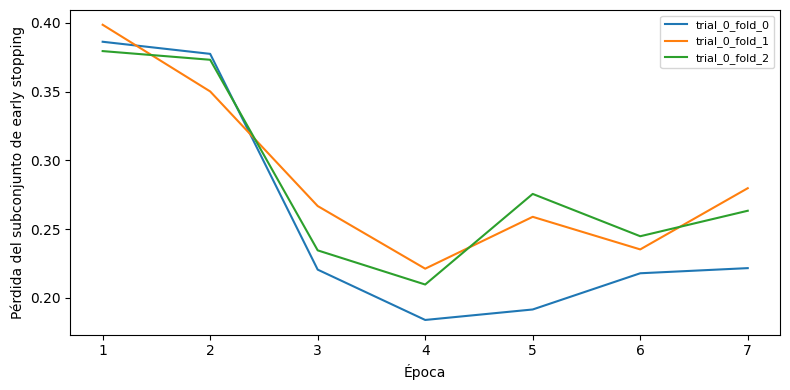

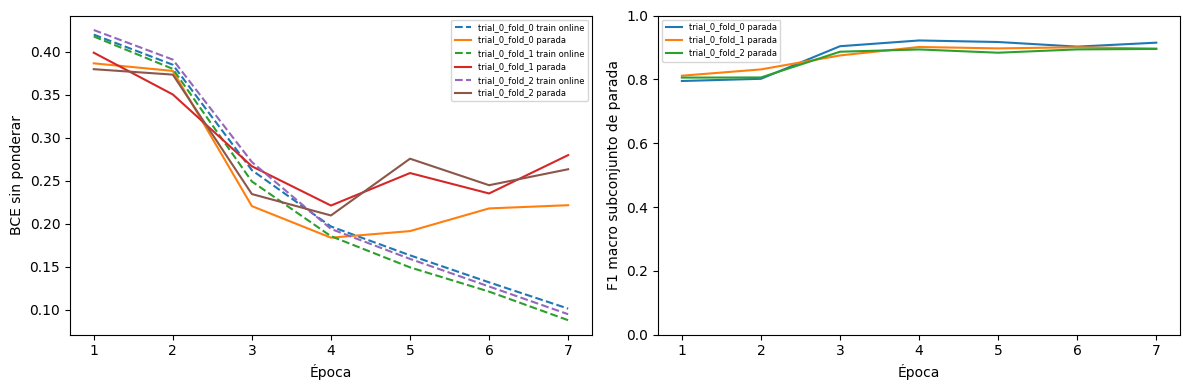

20:42:38 | stage_end | stage=deep_final | seconds=265.87


In [70]:
with stage_guard("deep_final"):
    FINAL, NORMALIZER, _, final_seconds = fit_deep(
        SELECTED,
        TRAIN_ROWS,
        TRAIN.y.to_numpy(),
        SELECTED["final_epochs"],
        "final_train",
    )

    runtime_rows.append({"phase": "ajuste_final_train", "seconds": final_seconds})

    tick = time.perf_counter()

    FINAL_SCORES = infer(FINAL, VALID_ROWS, VALID.y.to_numpy(), NORMALIZER)

    runtime_rows.append(
        {"phase": "prediccion_validacion", "seconds": time.perf_counter() - tick}
    )

    torch.save(
        {
            "state_dict": cpu_state(FINAL),
            "normalization_mean": NORMALIZER[0].tolist(),
            "normalization_std": NORMALIZER[1].tolist(),
            "model_kind": CFG["model_kind"],
            "params": SELECTED,
            "threshold": THRESHOLD,
            "score_type": SCORE_TYPE,
            "input_shape": list(INPUT_SHAPE),
            "class_map": {"0": "NON_EMERGENCY", "1": "EMERGENCY"},
            "config": CFG,
        },
        OUT / "models" / "model.pt",
    )

    write_json(
        OUT / "models" / "inference.json",
        {
            "threshold": THRESHOLD,
            "shape": INPUT_SHAPE,
            "normalization_mean": NORMALIZER[0].tolist(),
            "normalization_std": NORMALIZER[1].tolist(),
            "score_type": SCORE_TYPE,
            "preprocessing": "Numeric prepared log-Mel, standardize per band; add channel dimension",
        },
    )

    save_table(
        "selected_parameters.csv",
        [{"parameter": k, "value": json.dumps(v)} for k, v in SELECTED.items()],
    )

    history = pd.DataFrame(EPOCH_ROWS)

    plt.figure(figsize=(8, 4))

    for name, g in history[history.run.str.startswith(f"trial_{BEST_TRIAL}_")].groupby(
        "run"
    ):
        plt.plot(g.epoch, g.inner_stop_loss, label=name)

    plt.xlabel("Época")

    plt.ylabel("Pérdida del subconjunto de early stopping")

    plt.legend(fontsize=8)

    save_figure("curvas_entrenamiento")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for name, g in history[history.run.str.startswith(f"trial_{BEST_TRIAL}_")].groupby(
        "run"
    ):
        axes[0].plot(
            g.epoch,
            g.train_loss_unweighted,
            linestyle="--",
            label=name + " train online",
        )
        axes[0].plot(g.epoch, g.inner_stop_loss, label=name + " parada")
        axes[1].plot(g.epoch, g.inner_stop_f1, label=name + " parada")

    axes[0].set(xlabel="Época", ylabel="BCE sin ponderar")

    axes[1].set(xlabel="Época", ylabel="F1 macro subconjunto de parada", ylim=(0, 1))

    for ax in axes:
        ax.legend(fontsize=6)

    save_figure("loss_f1_detalle")

    reloaded, reloaded_normalization, reloaded_threshold = load_exported_model(
        OUT / "models/model.pt", device=DEVICE
    )

    sample_rows = VALID_ROWS[: min(8, len(VALID_ROWS))]

    reloaded_scores = infer(
        reloaded,
        sample_rows,
        VALID.y.to_numpy()[: len(sample_rows)],
        reloaded_normalization,
        amp=False,
    )

    reference = infer(
        unwrapped(FINAL),
        sample_rows,
        VALID.y.to_numpy()[: len(sample_rows)],
        NORMALIZER,
        amp=False,
    )

    if (
        not np.allclose(reloaded_scores, reference, rtol=1e-4, atol=1e-5)
        or reloaded_threshold != THRESHOLD
    ):
        fail("La recarga del modelo exportado no reproduce sus puntuaciones.")

    write_json(
        OUT / "reports/model_reload_check.json",
        {"passed": True, "rtol": 1e-4, "atol": 1e-5, "samples": len(sample_rows)},
    )

    del reloaded

## 7. Costo y artefactos

La latencia batch = 1 corresponde al forward sobre un tensor ya normalizado y residente en un dispositivo. El throughput utiliza el lote global. Estas mediciones excluyen captura, STFT, disco y transferencia de entrada; no certifican latencia extremo a extremo.


In [71]:
with stage_guard("deep_computation"):
    single = unwrapped(FINAL).eval()

    probe = read_representation_rows(VALID_ROWS[:1])[0].copy()

    probe = (probe - NORMALIZER[0][:, None]) / NORMALIZER[1][:, None]

    probe = torch.from_numpy(probe[None, None]).to(DEVICE)

20:42:38 | stage_start | stage=deep_computation
20:42:38 | stage_end | stage=deep_computation | seconds=0.0024708


In [72]:
def sync():
    for i in range(GPU_COUNT):
        torch.cuda.synchronize(i)

In [73]:
def timed_forward(model, x):
    with (
        torch.inference_mode(),
        torch.autocast(
            device_type=DEVICE.type, enabled=CFG["amp"] and DEVICE.type == "cuda"
        ),
    ):
        return model(x)

20:42:39 | stage_start | stage=deep_computation


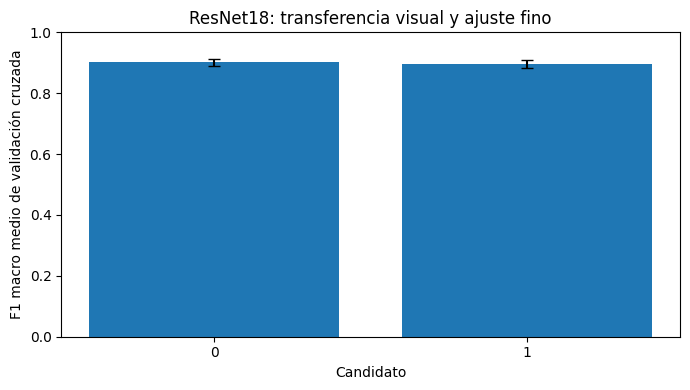

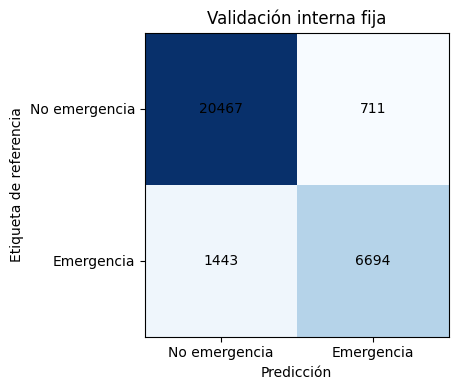

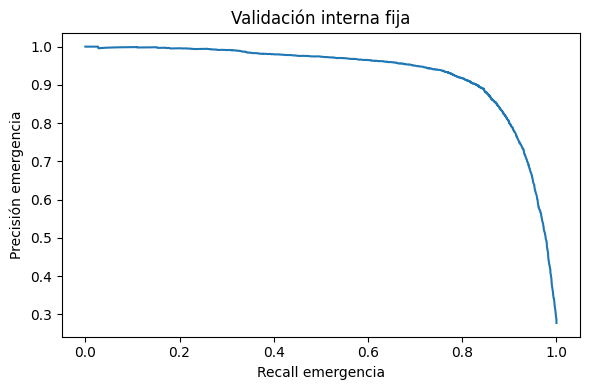

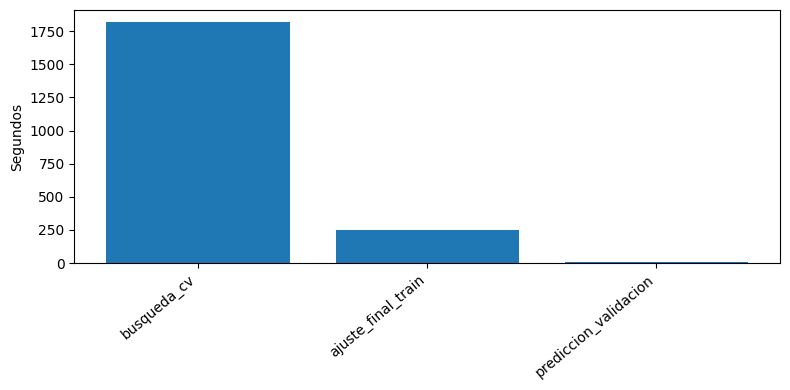

20:42:53 | training_complete | model=05_resnet18 | selected_params={'lr': 0.001, 'weight_decay': 0.0001, 'dropout': 0.3, 'final_epochs': 4} | threshold=0.65478


,n,accuracy,precision_emergency,recall_emergency,f1_macro,fpr,roc_auc,average_precision,tn,fp,fn,tp,threshold
0,29315,0.926522,0.903984,0.822662,0.905709,0.033573,0.962987,0.930496,20467,711,1443,6694,0.654784


RESULTADOS PARA DEVOLVER: /kaggle/working/entrenamiento/05_resnet18/20261012T200526_749323Z_resultados.zip
MODELOS PARA CONSERVAR: /kaggle/working/entrenamiento/05_resnet18/20261012T200526_749323Z_modelos.zip
LSSiren: no evaluado. Comparar únicamente ejecuciones con el mismo hash de folds: 3528557381804ea80cf8a9fd230bbe0c37f24e721094162609a2c41f83a2154d
Representación compacta directa: True
20:42:59 | stage_end | stage=deep_computation | seconds=20.439


In [74]:
with stage_guard("deep_computation"):
    for _ in range(CFG["latency_warmup"]):
        timed_forward(single, probe)

    sync()

    samples = []

    for _ in range(CFG["latency_repeats"]):
        sync()
        tick = time.perf_counter()
        timed_forward(single, probe)
        sync()
        samples.append((time.perf_counter() - tick) * 1000)

    batch = probe.repeat(CFG["batch_size"], 1, 1, 1)

    for _ in range(3):
        timed_forward(FINAL, batch)

    sync()

    tick = time.perf_counter()

    for _ in range(10):
        timed_forward(FINAL, batch)

    sync()

    elapsed = time.perf_counter() - tick

    save_table(
        "latency.csv",
        [
            {
                "scope": "forward on pre-normalized tensor resident on device; excludes disk, transfer and feature extraction",
                "batch_1_device": str(DEVICE),
                "p50_ms": np.percentile(samples, 50),
                "p95_ms": np.percentile(samples, 95),
                "repetitions": len(samples),
                "global_throughput_batch": CFG["batch_size"],
                "throughput_gpus": GPU_COUNT,
                "batch_segments_per_second": 10 * CFG["batch_size"] / elapsed,
                "parameters": sum(p.numel() for p in single.parameters()),
                "model_file_mib": (OUT / "models" / "model.pt").stat().st_size
                / 1024**2,
            }
        ],
    )

    make_reports(FINAL_SCORES, OOF, THRESHOLD, SELECTED, SUMMARY, runtime_rows)

    print("Representación compacta directa:", COMPACT_LAYOUT)

## Cierre de la ejecución

Comprueba el estado final y conserva los archivos de configuración, particiones, hashes y modelos.
Las tablas y figuras se generan al ejecutar esta notebook; la fuente del repositorio no incluye
resultados antiguos. Las nuevas salidas se revisarán después de su ejecución en Kaggle.
